<a href="https://colab.research.google.com/github/Balamurugan-T326/DEEP-LEARNING/blob/main/EXPERIMENT-8/PART-A%2CB%2CC%2CD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Part A: Import libraries and prepare the dataset

In [1]:
# Experiment 8: Train a Simple Autoencoder
# Roll Number: 24BAD016

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


Load the MNIST dataset

In [2]:

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training images shape:", x_train.shape)
print("Testing images shape:", x_test.shape)
print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images shape: (60000, 28, 28)
Testing images shape: (10000, 28, 28)
Training samples: 60000
Testing samples: 10000


Display sample images

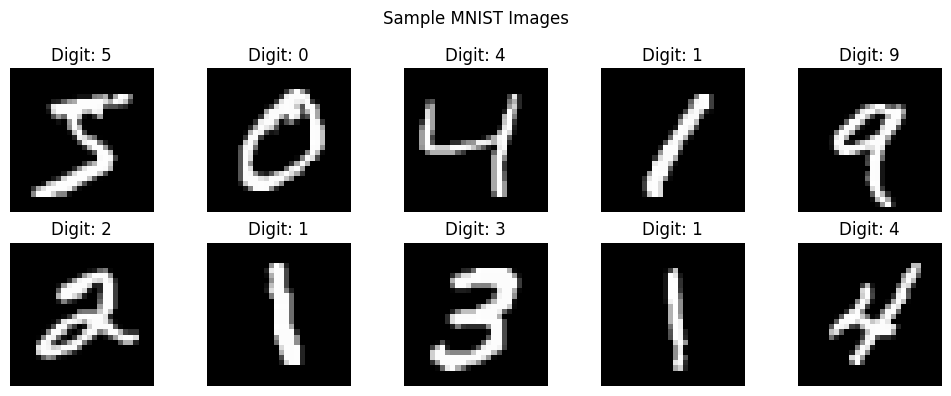

In [3]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.suptitle("Sample MNIST Images")
plt.tight_layout()
plt.show()

Preprocess the dataset

In [4]:
# Normalize pixel values to the range [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten each 28 x 28 image into 784 features
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Preprocessed training data:", x_train.shape)
print("Preprocessed testing data:", x_test.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Preprocessed training data: (60000, 784)
Preprocessed testing data: (10000, 784)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


Part B: Implement the Encoder and Decoder

In [5]:
# Input layer: 784 features
input_layer = Input(shape=(784,), name="input_layer")

# Encoder: compress the input
encoded = Dense(128, activation="relu", name="encoder_hidden")(input_layer)
latent = Dense(32, activation="relu", name="latent_layer")(encoded)

# Decoder: reconstruct the input
decoded = Dense(128, activation="relu", name="decoder_hidden")(latent)
output_layer = Dense(784, activation="sigmoid", name="output_layer")(decoded)

# Create complete autoencoder
autoencoder = Model(input_layer, output_layer, name="Autoencoder")

# Create encoder model separately
encoder = Model(input_layer, latent, name="Encoder")

# Create decoder model separately
latent_input = Input(shape=(32,), name="latent_input")
decoder_hidden = autoencoder.get_layer("decoder_hidden")(latent_input)
decoder_output = autoencoder.get_layer("output_layer")(decoder_hidden)
decoder = Model(latent_input, decoder_output, name="Decoder")

print("Autoencoder architecture created successfully!")

Autoencoder architecture created successfully!


Display model summaries

In [6]:
print("ENCODER SUMMARY")
encoder.summary()

print("\nDECODER SUMMARY")
decoder.summary()

print("\nAUTOENCODER SUMMARY")
autoencoder.summary()

ENCODER SUMMARY


Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_hidden (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_layer (Dense)            │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

...

Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_hidden (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_layer (Dense)            │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_hidden (Dense)          │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

Part C: Compile and Train the Autoencoder

In [7]:
autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

print("Autoencoder compiled successfully!")

Autoencoder compiled successfully!


Train the model

In [8]:
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test),
    verbose=1
)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - loss: 0.2314 - val_loss: 0.1498
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - loss: 0.1330 - val_loss: 0.1187
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.1153 - val_loss: 0.1096
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.1086 - val_loss: 0.1045
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.1037 - val_loss: 0.1003
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.1003 - val_loss: 0.0979
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0981 - val_loss: 0.0962
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0966 - val_loss: 0.0955
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0955 - val_loss: 0.0938
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.0946 - val_loss: 0.0933


Plot training and validation loss

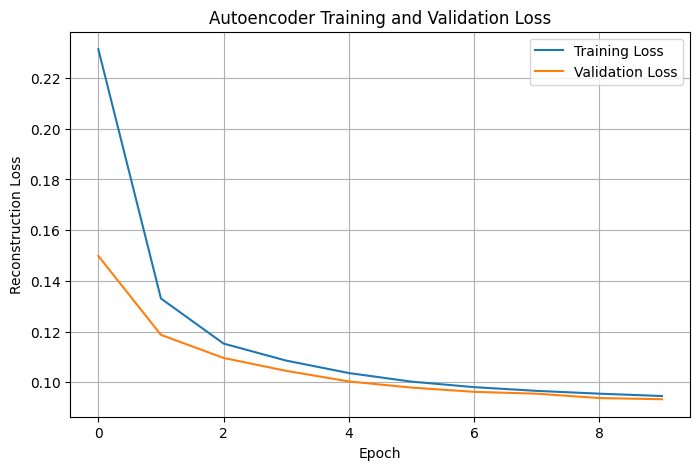

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss")
plt.legend()
plt.grid(True)
plt.show()

Part D: Dimensionality Reduction, Feature Learning and Reconstruction

In [10]:
# Encode test images into 32-dimensional latent vectors
latent_features = encoder.predict(x_test, verbose=0)

print("Original input dimension:", x_test.shape[1])
print("Latent dimension:", latent_features.shape[1])
print("Latent feature matrix shape:", latent_features.shape)

Original input dimension: 784
Latent dimension: 32
Latent feature matrix shape: (10000, 32)


Reconstruct the images

In [12]:
# Reconstruct test images using the trained autoencoder
reconstructed_images = autoencoder.predict(x_test, verbose=0)

print("Original images shape:", x_test.shape)
print("Reconstructed images shape:", reconstructed_images.shape)

Original images shape: (10000, 784)
Reconstructed images shape: (10000, 784)


Compare original and reconstructed images

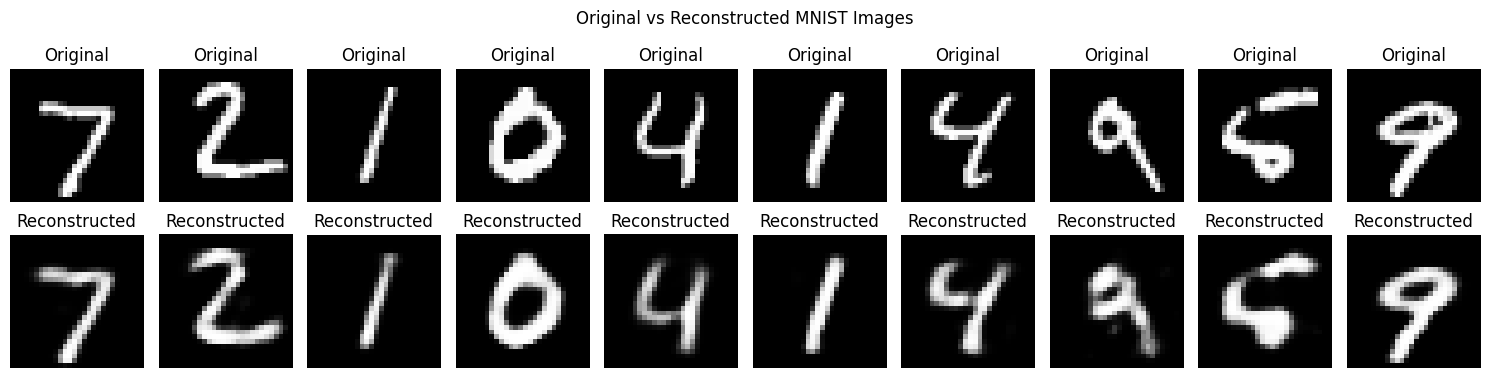

In [13]:
n = 10

plt.figure(figsize=(15, 4))

for i in range(n):
    # Original images
    plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Reconstructed images
    plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.suptitle("Original vs Reconstructed MNIST Images")
plt.tight_layout()
plt.show()

Evaluate reconstruction performance

In [14]:
# Calculate Mean Squared Error
mse = np.mean((x_test - reconstructed_images) ** 2)

print("Mean Squared Reconstruction Error:", mse)

# Save the trained model
autoencoder.save("mnist_autoencoder.keras")

print("Model saved successfully!")

Mean Squared Reconstruction Error: 0.010289108
Model saved successfully!
